# Notebook 2: Encoding Time Series Menjadi Gambar

Notebook ini mengubah segmen 20 hari dari Notebook 1 menjadi gambar dengan 14 jenis encoding (GADF, GASF, dan 12 varian MTF), lalu menghitung statistik matriksnya (mean, SD, dan jumlah nilai unik) untuk tiap encoding. Metodenya mengikuti Rahadian et al. (2023).

Jalankan setelah Notebook 1. Hasil disimpan ke `data/processed/`, `figures/`, dan `results/`.

## 1. Persiapan

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from pyts.image import GramianAngularField, MarkovTransitionField

warnings.filterwarnings('ignore')
SEED = 42
SEG_LEN = 20
IMG = 150
ROOT = Path('..')
PROC, FIG, RES = ROOT/'data/processed', ROOT/'figures', ROOT/'results'

d = np.load(PROC/'segmen.npz')
meta = pd.read_csv(PROC/'segmen_meta.csv')
normal_z, anomali_z, mask = d['normal_z'], d['anomali_z'], d['mask_anomali']
game_id = d['game_id']
N = len(normal_z)
X = np.vstack([normal_z, anomali_z])            # N segmen normal, lalu N segmen anomali
y = np.r_[np.zeros(N, int), np.ones(N, int)]    # 0 = normal, 1 = anomali
print('Jumlah segmen:', X.shape, '| nilai z: min', X.min().round(2), 'maks', X.max().round(2))

Jumlah segmen: (2458, 20) | nilai z: min -8.48 maks 6.27


## 2. Daftar 14 encoding

Parameter lain dibiarkan default seperti di paper (`image_size=1.0`, `sample_range=(-1, 1)`, `overlapping=False`, `flatten=False`). GAF menghasilkan nilai di rentang [-1, 1], sedangkan MTF di rentang [0, 1].

In [2]:
ENC = {'GADF': GramianAngularField(method='difference'), 'GASF': GramianAngularField(method='summation')}
for strat in ['uniform', 'quantile', 'normal']:
    for b in [2, 4, 5, 10]:
        ENC[f'MTF {strat.capitalize()} {b}'] = MarkovTransitionField(n_bins=b, strategy=strat)
VR = {n: (-1, 1) if n.startswith('GA') else (0, 1) for n in ENC}    # rentang warna: GAF [-1,1], MTF [0,1]
print(len(ENC), 'encoding:', list(ENC))

14 encoding: ['GADF', 'GASF', 'MTF Uniform 2', 'MTF Uniform 4', 'MTF Uniform 5', 'MTF Uniform 10', 'MTF Quantile 2', 'MTF Quantile 4', 'MTF Quantile 5', 'MTF Quantile 10', 'MTF Normal 2', 'MTF Normal 4', 'MTF Normal 5', 'MTF Normal 10']


## 3. Mengubah segmen menjadi matriks 20 x 20

Setiap segmen diubah menjadi matriks 20 x 20. Waktunya dicatat (seperti kolom "TS to Matrix" di Tabel 14 paper). Satu kali pemanasan (encoding seluruh data) dilakukan dulu supaya waktu kompilasi numba di pyts tidak ikut terhitung.

In [3]:
for e in ENC.values():
    e.fit_transform(X)

MAT, t_encode = {}, {}
for name, e in ENC.items():
    t0 = time.perf_counter()
    MAT[name] = e.fit_transform(X)
    t_encode[name] = time.perf_counter() - t0
print('Bentuk tiap matriks:', MAT['GADF'].shape)

Bentuk tiap matriks: (2458, 20, 20)


## 4. Mengubah matriks menjadi gambar 150 x 150

Setiap nilai matriks dipetakan ke warna dengan colormap `rainbow` (nilai terendah ungu, tertinggi merah), baris diurutkan dengan `origin='lower'`, lalu diperbesar menjadi 150 x 150 piksel. Pembesaran memakai metode tetangga terdekat supaya satu nilai matriks tetap menjadi satu warna yang jelas.

Gambar tidak disimpan ke disk (ukurannya terlalu besar). Pada Tahap 3, gambar dibuat ulang dari matriks. Di sini waktu konversinya saja yang dicatat.

In [4]:
cmap = plt.get_cmap('rainbow')
pix = (np.arange(IMG) * SEG_LEN) // IMG

def to_image(mats, vmin, vmax):
    scaled = np.clip((mats - vmin) / (vmax - vmin), 0, 1)
    rgb = (cmap(scaled)[..., :3] * 255).astype(np.uint8)
    rgb = rgb[:, ::-1]
    return rgb[:, pix][:, :, pix]

t_image = {}
for name in ENC:
    t0 = time.perf_counter()
    for s in range(0, len(X), 500):
        _ = to_image(MAT[name][s:s+500], *VR[name])
    t_image[name] = time.perf_counter() - t0

waktu = pd.DataFrame({'encoding': list(ENC), 'matriks_detik': [t_encode[n] for n in ENC],
                      'gambar_detik': [t_image[n] for n in ENC]})
waktu['total_detik'] = waktu.matriks_detik + waktu.gambar_detik
waktu.round(3).to_csv(RES/'waktu_encoding.csv', index=False)
waktu.round(3)

,encoding,matriks_detik,gambar_detik,total_detik
0,GADF,0.003,0.192,0.194
1,GASF,0.003,0.175,0.178
2,MTF Uniform 2,0.003,0.181,0.184
3,MTF Uniform 4,0.003,0.178,0.181
4,MTF Uniform 5,0.003,0.176,0.180
5,MTF Uniform 10,0.004,0.177,0.181
6,MTF Quantile 2,0.004,0.178,0.181
7,MTF Quantile 4,0.005,0.183,0.187
8,MTF Quantile 5,0.005,0.212,0.217
9,MTF Quantile 10,0.009,0.225,0.234


## 5. Statistik matriks: mean, SD, dan count

Untuk tiap matriks dihitung mean, simpangan baku (SD), dan jumlah nilai unik (count), seperti di paper. Nilai-nilai ini dirata-ratakan untuk semua segmen normal dan semua segmen anomali. Selisih absolut rata-rata keduanya adalah Δmean, ΔSD, dan Δcount.

In [5]:
def matrix_stats(M):
    flat = M.reshape(len(M), -1)
    return flat.mean(axis=1), flat.std(axis=1), np.array([len(np.unique(r)) for r in flat])

rows, per_seg = [], {}
for name in ENC:
    m, s, c = matrix_stats(MAT[name])
    per_seg[name] = (m, s, c)
    rows.append({'encoding': name,
                 'mean_normal': m[:N].mean(), 'mean_anomali': m[N:].mean(),
                 'sd_normal': s[:N].mean(), 'sd_anomali': s[N:].mean(),
                 'count_normal': c[:N].mean(), 'count_anomali': c[N:].mean()})
stat = pd.DataFrame(rows)
stat['delta_mean'] = (stat.mean_normal - stat.mean_anomali).abs()
stat['delta_sd'] = (stat.sd_normal - stat.sd_anomali).abs()
stat['delta_count'] = (stat.count_normal - stat.count_anomali).abs()
stat.round(3).to_csv(RES/'delta_per_encoding.csv', index=False)
stat.round(3)

,encoding,mean_normal,mean_anomali,sd_normal,sd_anomali,count_normal,count_anomali,delta_mean,delta_sd,delta_count
0,GADF,0.000,0.000,0.654,0.498,359.493,361.125,0.000,0.155,1.632
1,GASF,-0.464,-0.424,0.520,0.456,208.318,208.535,0.040,0.063,0.217
2,MTF Uniform 2,0.558,0.723,0.262,0.226,3.843,3.858,0.165,0.036,0.015
3,MTF Uniform 4,0.324,0.565,0.265,0.287,6.912,5.771,0.241,0.022,1.141
4,MTF Uniform 5,0.273,0.541,0.262,0.295,7.022,5.873,0.268,0.033,1.149
5,MTF Uniform 10,0.164,0.363,0.252,0.290,6.041,6.643,0.199,0.038,0.601
6,MTF Quantile 2,0.500,0.500,0.227,0.165,3.990,3.866,0.000,0.061,0.124
7,MTF Quantile 4,0.250,0.250,0.213,0.191,5.679,5.531,0.000,0.022,0.149
8,MTF Quantile 5,0.200,0.200,0.213,0.198,5.016,4.806,0.000,0.014,0.211
9,MTF Quantile 10,0.100,0.100,0.220,0.219,3.028,3.023,0.000,0.001,0.006


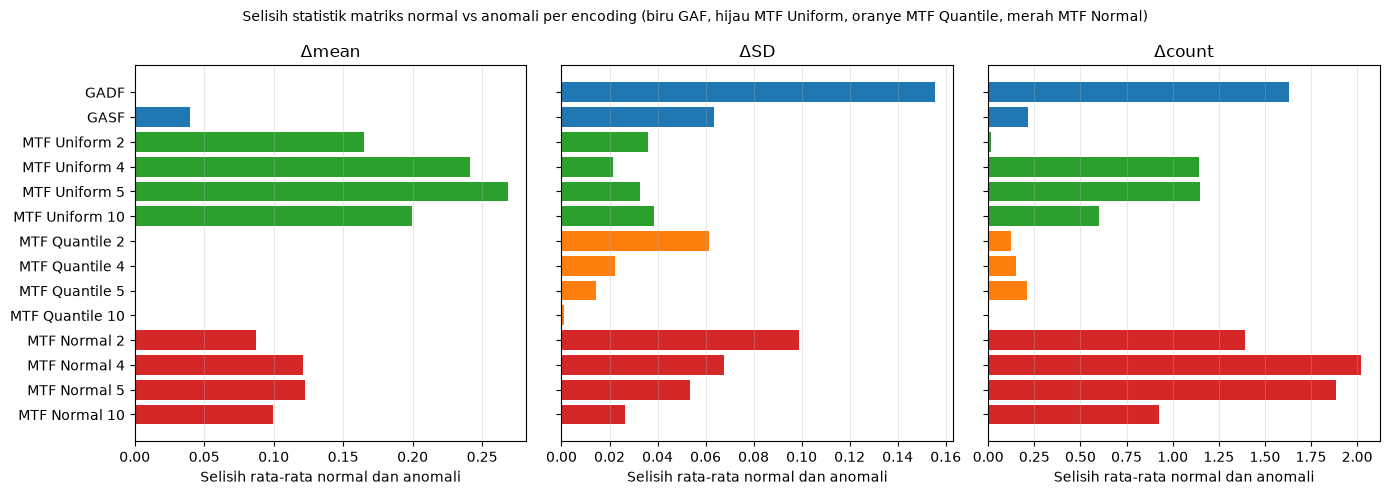

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
colors = ['tab:blue'] * 2 + ['tab:green'] * 4 + ['tab:orange'] * 4 + ['tab:red'] * 4
for ax, col, ttl in zip(axes, ['delta_mean', 'delta_sd', 'delta_count'], ['Δmean', 'ΔSD', 'Δcount']):
    ax.barh(stat.encoding, stat[col], color=colors)
    ax.set_title(ttl); ax.set_xlabel('Selisih rata-rata normal dan anomali'); ax.grid(alpha=0.3, axis='x')
axes[0].invert_yaxis()
fig.suptitle('Selisih statistik matriks normal vs anomali per encoding (biru GAF, hijau MTF Uniform, oranye MTF Quantile, merah MTF Normal)', fontsize=10)
fig.tight_layout(); fig.savefig(FIG/'07_delta_per_encoding.png', dpi=150); plt.show()

## 6. Gambar normal dan anomali berdampingan

Tiga segmen contoh (sama dengan contoh di Notebook 1). Untuk tiap segmen, atas: deret waktu terstandar. Tengah: gambar dari segmen normal. Bawah: gambar dari segmen anomali yang sudah disuntik. Warna ungu berarti nilai matriks rendah dan merah berarti tinggi. Lima encoding ditampilkan mewakili setiap keluarga.

[('Terraria', '2011-09-12'), ('Rainbow Six Siege', '2018-09-16'), ("Garry's Mod", '2023-06-05')]


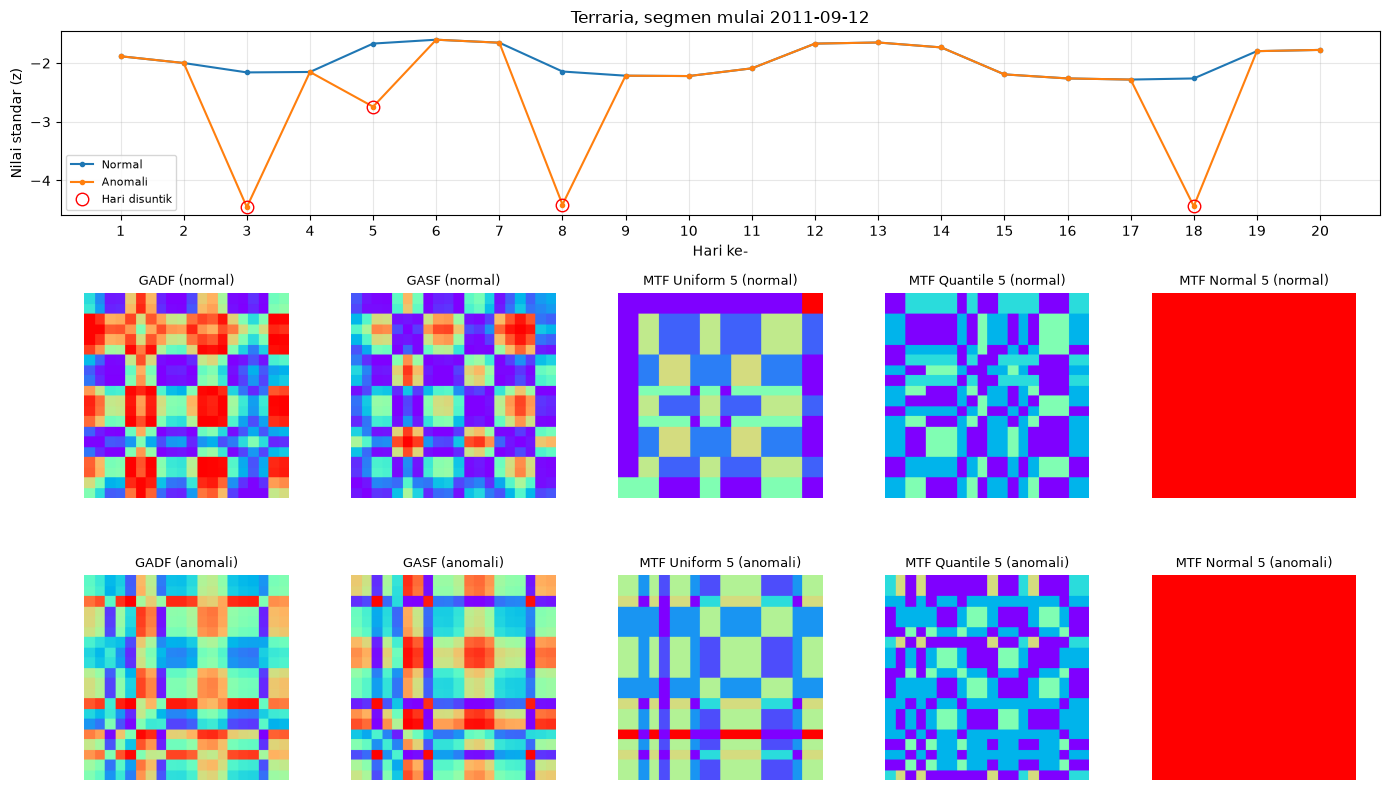

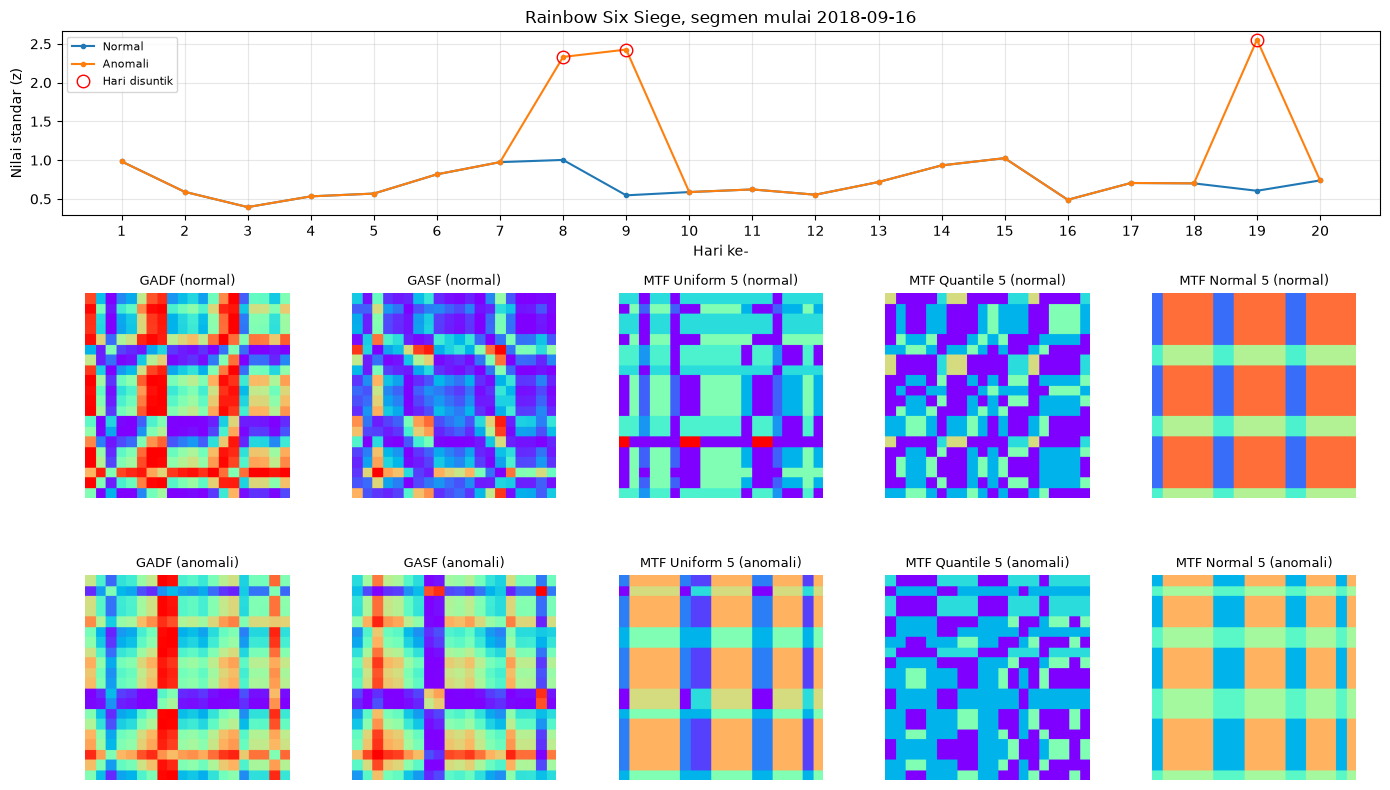

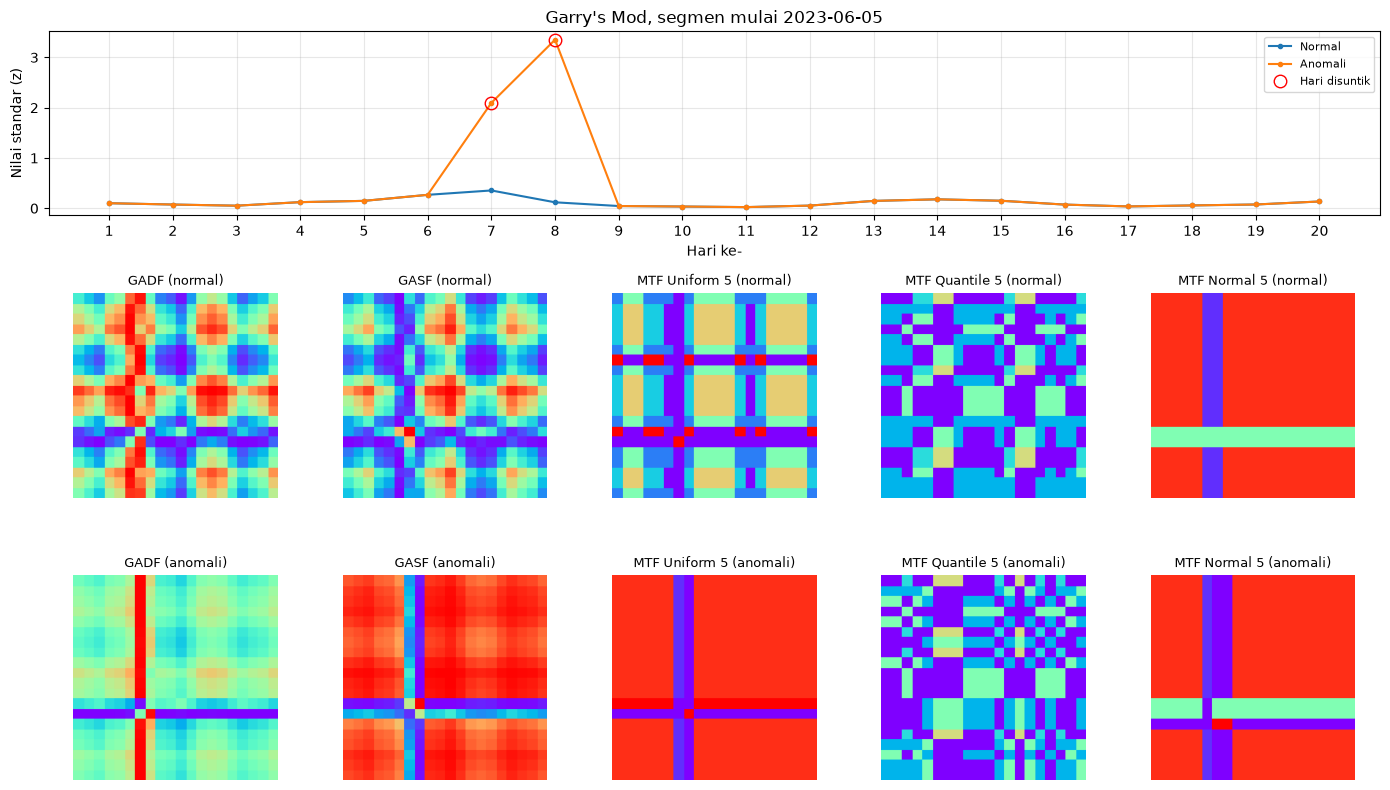

In [7]:
bump = meta.ada_lonjakan_asli.values
rng2 = np.random.default_rng(SEED + 1)
chosen = []
for gi in rng2.choice(6, size=3, replace=False):
    chosen.append(rng2.choice(np.where((game_id == gi) & (~bump))[0]))
GN = dict(zip(d['games'], ['Dark Souls 3', 'Euro Truck Simulator 2', "Garry's Mod", 'Rainbow Six Siege', 'Stardew Valley', 'Terraria']))
print([(GN[meta.game[i]], meta.tanggal_mulai[i]) for i in chosen])

def image_of(name, i, anomali):
    return to_image(MAT[name][[i + N * anomali]], *VR[name])[0]

REP = ['GADF', 'GASF', 'MTF Uniform 5', 'MTF Quantile 5', 'MTF Normal 5']
x = np.arange(1, SEG_LEN + 1)
for k, i in enumerate(chosen, 1):
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(3, 5, height_ratios=[0.9, 1, 1])
    ax = fig.add_subplot(gs[0, :])
    ax.plot(x, normal_z[i], 'o-', ms=3, label='Normal'); ax.plot(x, anomali_z[i], 'o-', ms=3, label='Anomali')
    ax.plot(x[mask[i]], anomali_z[i][mask[i]], 'o', color='red', ms=9, mfc='none', label='Hari disuntik')
    ax.set_xticks(x); ax.set_xlabel('Hari ke-'); ax.set_ylabel('Nilai standar (z)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_title(f'{GN[meta.game[i]]}, segmen mulai {meta.tanggal_mulai[i]}')
    for c, name in enumerate(REP):
        for r, lab in enumerate(['normal', 'anomali']):
            a = fig.add_subplot(gs[r + 1, c]); a.imshow(image_of(name, i, r)); a.axis('off'); a.set_title(f'{name} ({lab})', fontsize=9)
    fig.tight_layout(); fig.savefig(FIG/f'05_pasangan_gambar_{k}.png', dpi=150); plt.show()

## 7. Mosaik 14 encoding untuk satu segmen

Satu segmen yang sama diubah dengan keempat belas encoding. Baris 1 dan 3 untuk segmen normal, baris 2 dan 4 untuk versi anomalinya.

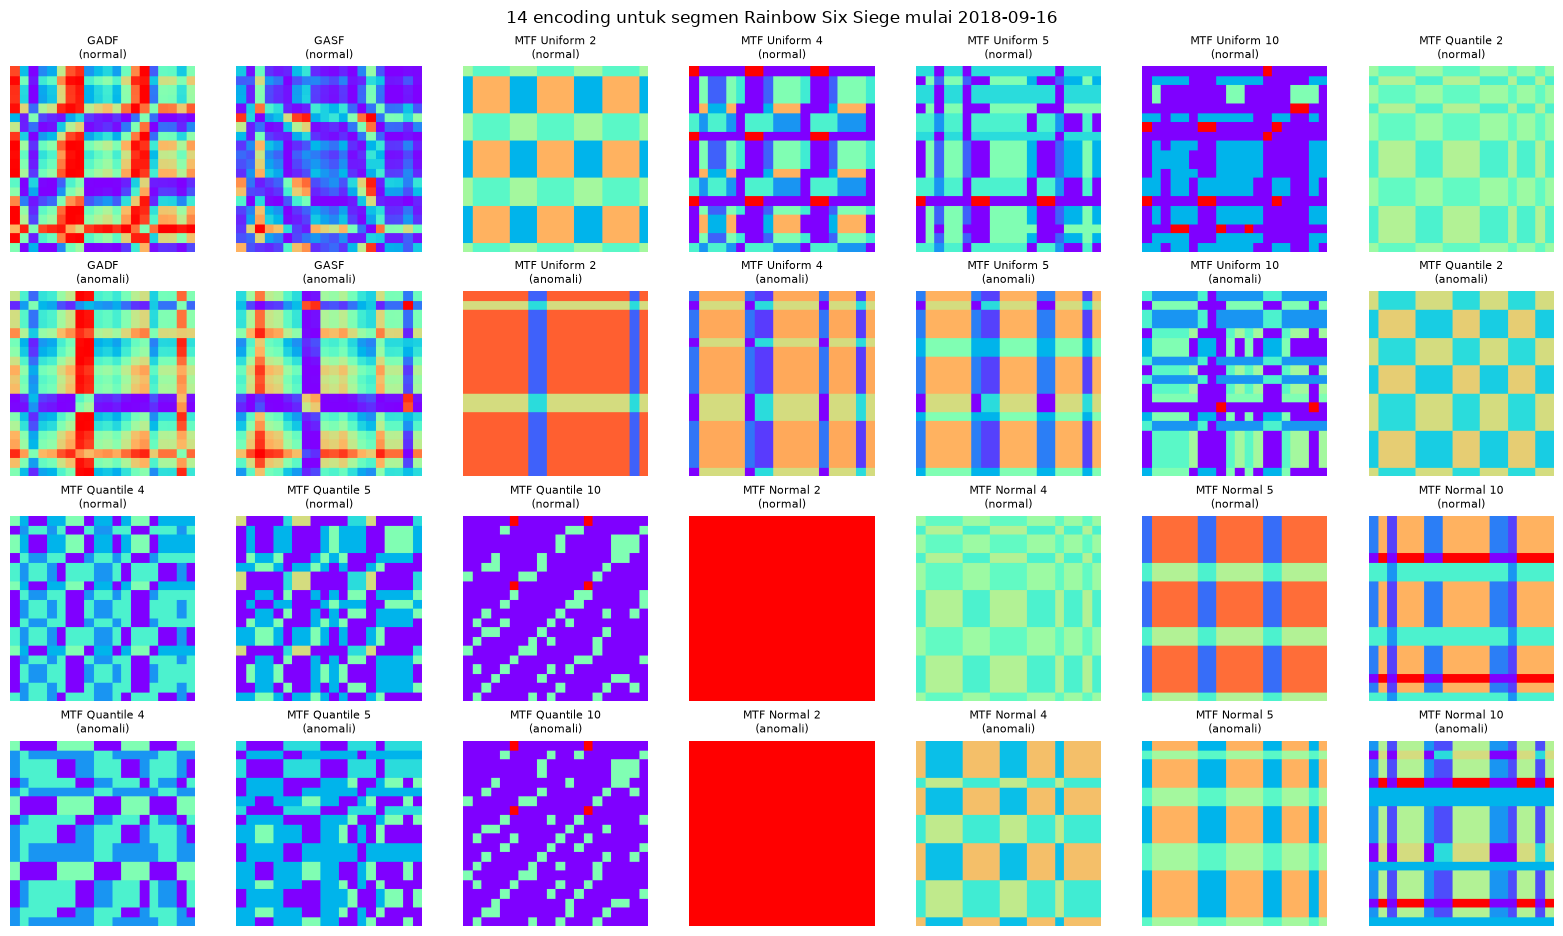

In [8]:
i = chosen[1]
names = list(ENC)
fig, axes = plt.subplots(4, 7, figsize=(16, 9.5))
for j, name in enumerate(names):
    r0 = 0 if j < 7 else 2
    for r, lab in enumerate(['normal', 'anomali']):
        a = axes[r0 + r, j % 7]; a.imshow(image_of(name, i, r)); a.axis('off'); a.set_title(f'{name}\n({lab})', fontsize=8)
fig.suptitle(f'14 encoding untuk segmen {GN[meta.game[i]]} mulai {meta.tanggal_mulai[i]}')
fig.tight_layout(); fig.savefig(FIG/'06_mosaik_14_encoding.png', dpi=150); plt.show()

## 8. MTF Normal: apakah gambarnya masih merah semua?

Di paper, MTF Normal menghasilkan gambar merah semua (akurasi 50%). Penyebabnya ada di cara pyts bekerja. Strategi `normal` membagi nilai ke bin memakai batas tetap dari kuantil distribusi normal baku, yaitu N(0, 1), dan batas ini langsung dipakai pada data apa adanya. Strategi `uniform` dan `quantile` menghitung batas dari tiap segmen sendiri, sehingga tidak terpengaruh skala data.

Jika seluruh nilai segmen jatuh ke satu bin yang sama (misalnya karena nilainya jauh di atas batas teratas), matriks transisinya hanya berisi satu angka, yaitu 1, sehingga seluruh gambar berwarna merah. Pada data tegangan 4 sampai 5 V di paper, hal itu terjadi di semua segmen.

Pada data kita, nilai sudah distandarisasi sehingga berada di sekitar 0, tepat di rentang batas bin. Berikut perbandingannya dengan data yang belum distandarisasi (hanya diubah ke log10, nilainya sekitar 3,5 sampai 5,7).

In [9]:
raw_log = np.log10(np.vstack([d['normal_raw'], d['anomali_raw']]))
rows = []
for b in [2, 4, 5, 10]:
    r = {'n_bins': b}
    for lab, data in [('terstandar', X), ('mentah_log10', raw_log)]:
        M = MarkovTransitionField(n_bins=b, strategy='normal').fit_transform(data)
        const = M.reshape(len(M), -1).std(axis=1) == 0
        r[f'persen_gambar_seragam_normal_{lab}'] = 100 * const[:N].mean()
        r[f'persen_gambar_seragam_anomali_{lab}'] = 100 * const[N:].mean()
    rows.append(r)
mtfn = pd.DataFrame(rows).round(1)
mtfn.to_csv(RES/'mtf_normal_seragam.csv', index=False)
mtfn

,n_bins,persen_gambar_seragam_normal_terstandar,persen_gambar_seragam_anomali_terstandar,persen_gambar_seragam_normal_mentah_log10,persen_gambar_seragam_anomali_mentah_log10
0,2,66.8,19.0,100.0,100.0
1,4,31.2,6.7,100.0,100.0
2,5,22.7,5.4,100.0,100.0
3,10,8.5,2.5,100.0,100.0


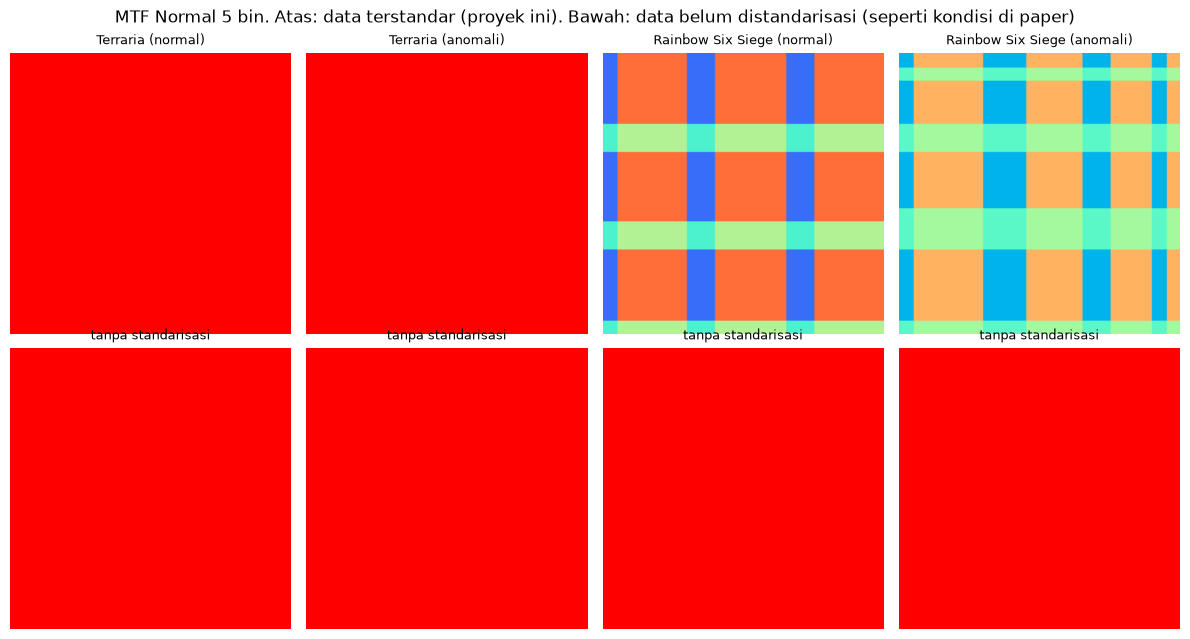

In [10]:
M_raw5 = MarkovTransitionField(n_bins=5, strategy='normal').fit_transform(raw_log)
a_i, b_i = chosen[0], chosen[1]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for c, (idx, lab) in enumerate([(a_i, 'normal'), (a_i + N, 'anomali'), (b_i, 'normal'), (b_i + N, 'anomali')]):
    axes[0, c].imshow(to_image(MAT['MTF Normal 5'][[idx]], 0, 1)[0]); axes[0, c].set_title(f'{GN[meta.game[idx % N]]} ({lab})', fontsize=9)
    axes[1, c].imshow(to_image(M_raw5[[idx]], 0, 1)[0]); axes[1, c].set_title('tanpa standarisasi', fontsize=9)
    axes[0, c].axis('off'); axes[1, c].axis('off')
fig.suptitle('MTF Normal 5 bin. Atas: data terstandar (proyek ini). Bawah: data belum distandarisasi (seperti kondisi di paper)')
fig.tight_layout(); fig.savefig(FIG/'08_mtf_normal_standar_vs_mentah.png', dpi=150); plt.show()

## 9. Pemeriksaan tambahan: gambar seragam pada semua encoding MTF dan batas nilai unik

Dua hal yang perlu diketahui sebelum training. Pertama, seberapa banyak gambar yang seragam (satu warna) pada tiap encoding MTF, karena gambar seragam tidak membawa informasi apa pun bagi CNN. Kedua, jumlah nilai unik pada GAF: dari 20 titik diperoleh paling banyak 190 pasangan berbeda (GASF, simetris) atau sekitar 380 (GADF), dan pada data kita hampir semua nilai harian berbeda, sehingga count mendekati batas itu.

In [11]:
rows = []
for name in ENC:
    if name.startswith('MTF'):
        flat = MAT[name].reshape(len(X), -1)
        const = flat.std(axis=1) == 0
        rows.append({'encoding': name, 'persen_seragam_normal': 100 * const[:N].mean(), 'persen_seragam_anomali': 100 * const[N:].mean()})
const_tbl = pd.DataFrame(rows).round(1)
const_tbl.to_csv(RES/'gambar_seragam_mtf.csv', index=False)
print(const_tbl.to_string(index=False))
print()
for name in ['GADF', 'GASF']:
    c = per_seg[name][2]
    print(f'{name}: count per matriks min {c.min()}, maks {c.max()}, rata-rata normal {c[:N].mean():.1f}, anomali {c[N:].mean():.1f}')

       encoding  persen_seragam_normal  persen_seragam_anomali
  MTF Uniform 2                    0.0                     0.0
  MTF Uniform 4                    0.0                     0.0
  MTF Uniform 5                    0.0                     0.0
 MTF Uniform 10                    0.0                     0.0
 MTF Quantile 2                    0.0                     0.0
 MTF Quantile 4                    0.0                     0.0
 MTF Quantile 5                    0.0                     0.0
MTF Quantile 10                    0.0                     0.0
   MTF Normal 2                   66.8                    19.0
   MTF Normal 4                   31.2                     6.7
   MTF Normal 5                   22.7                     5.4
  MTF Normal 10                    8.5                     2.5

GADF: count per matriks min 183, maks 381, rata-rata normal 359.5, anomali 361.1
GASF: count per matriks min 105, maks 210, rata-rata normal 208.3, anomali 208.5


## 10. Menyimpan matriks

Matriks semua encoding disimpan supaya Tahap 3 tidak perlu mengulang encoding. Urutan data: N segmen normal lebih dulu, lalu N segmen anomali dengan urutan segmen yang sama seperti `segmen_meta.csv`.

In [12]:
np.savez_compressed(PROC/'matriks_encoding.npz', y=y, **{n.replace(' ', '_'): MAT[n].astype(np.float32) for n in ENC})
print('Tersimpan:', (PROC/'matriks_encoding.npz').stat().st_size // 1024**2, 'MB')

Tersimpan: 6 MB
